#### Initial Toy Model for Final Project

Initial Commit Date: 11/04/26

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation, rc

In [16]:
kappa = 1.09e-6
H = 23
dz = 1

# Spatial discretization
M = int(round(H / dz))
z = np.linspace(0, H, M + 1)

# Temporal discretization
r = 0.4
dt = r * dz**2 / kappa

# Boundary conditions
T_s, T_b = 0.0, -0.8

# Convergence parameters
tol = 1e-4
max_steps = 20_000_000

# Initial condition
p = np.poly1d([0.002011, -0.05199, 0.1666, -0.8])

# Analytical steady-state solution
T_ss = T_b + (T_s - T_b) * z / H

# Allocate temperature history
T = np.zeros((max_steps + 1, M + 1))

T[0, :] = p(z)
T[0, 0], T[0, -1] = T_b, T_s

In [17]:
# Forward Euler + centered differences
for n in range(max_steps):

    T[n+1, 1:-1] = (
        T[n, 1:-1]
        + r * (T[n, 2:] - 2*T[n, 1:-1] + T[n, :-2])
    )

    # Enforce boundary conditions
    T[n+1, 0], T[n+1, -1] = T_b, T_s

    # Check convergence
    err = np.max(np.abs(T[n+1] - T_ss))

    if err < tol:
        break

# Trim unused time steps
T = T[:n+2, :]

# Time array
t = np.arange(len(T)) * dt



Converged at step: 1347
Simulation time: 15.69 years
Maximum error: 9.99e-05


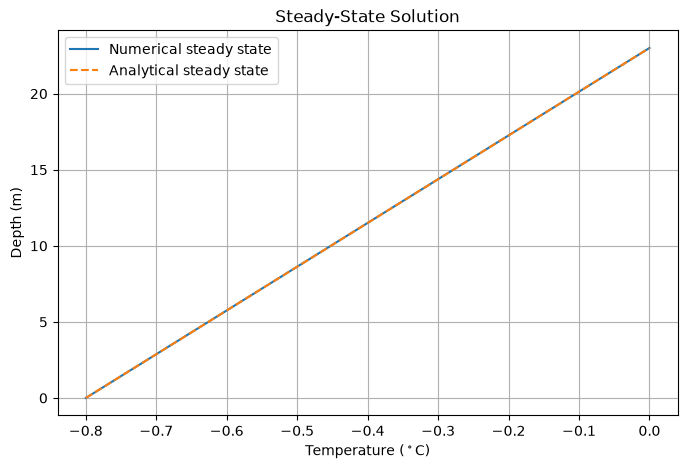

In [18]:
print(f"Converged at step: {n+1}")
print(f"Simulation time: {t[-1]/3.15e7:.2f} years")
print(f"Maximum error: {err:.2e}")
plt.figure(figsize=(8, 5))

plt.plot(T[-1,:],z, label="Numerical steady state")
plt.plot(T_ss,z, "--", label="Analytical steady state")

plt.ylabel("Depth (m)")
plt.xlabel("Temperature ($^\circ$C)")
plt.title("Steady-State Solution")
plt.legend()
plt.grid()

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
plt.close()

ax.set_ylim(0, H)
ax.set_xlim(np.min(T), np.max(T))
ax.set_ylabel("Depth (m)")
ax.set_xlabel("Temperature")
ax.set_title("Ice Temperature Evolution")

line, = ax.plot([], [], lw=2, label="Temperature")
ax.plot(T_ss, z, "--", label="Steady State")
ax.legend()

def init():
    line.set_data([], [])
    return (line,)

def animate(j):
    T_j = T[j, :]
    line.set_data(T_j, z)

    time_years = t[j] / 3.15e7
    ax.set_title(f"Temperature Evolution: t = {time_years:.2f} years")

    return (line,)

anim = animation.FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=len(T),
    interval=5,
    blit=True
)

rc('animation', html='jshtml')
plt.rcParams['animation.embed_limit'] = 100  # 100 MB
anim

Animation size has reached 21005889 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
